Dataset: 60,919 rows x 25 cols
Total Revenue: 81014827.02 | Total Discount: 60062467.53

--- Business Segment Summary ---
                   orders  units      revenue  avg_discount_pct  revenue_share_pct
business_segment                                                                 
Bikes              24826  75063  66827511.81             42.52              82.49
Components         18698  49044  11807764.77             41.26              14.57
Clothing           12293  64569   1801581.16             40.89               2.22
Accessories         5102  25840    577969.28             41.41               0.71


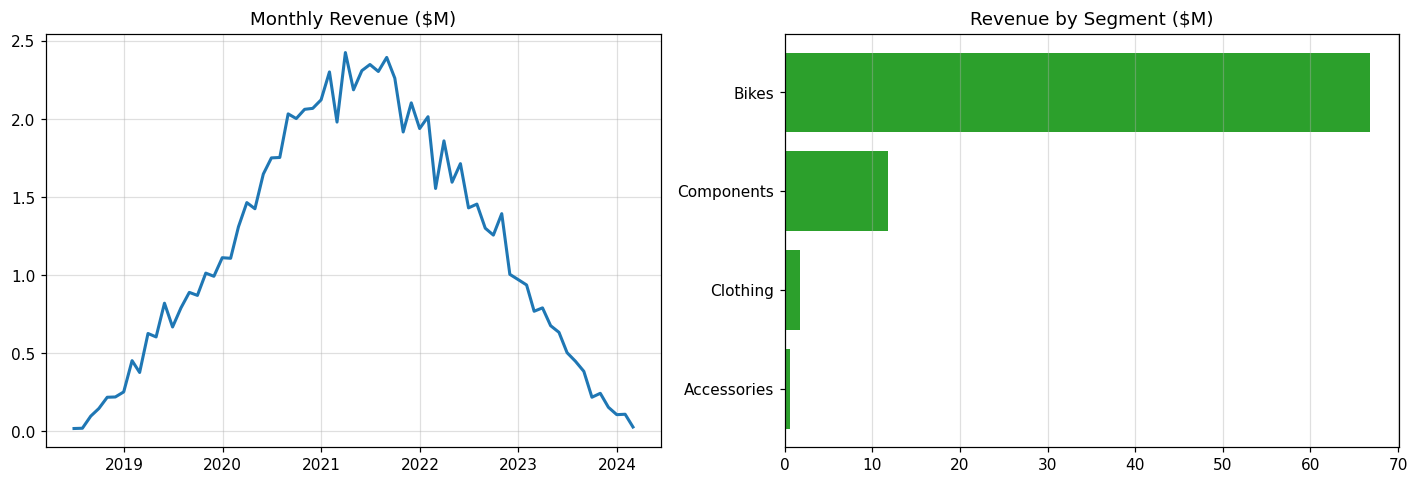

In [1]:
print(f"Dataset: {df.shape[0]:,} rows x {df.shape[1]} cols")
print("Total Revenue:", round(df['revenue'].sum(), 2), "| Total Discount:", round(df['discount_value'].sum(), 2))
print("\n--- Business Segment Summary ---\n", seg.round(2).to_string())
monthly = df.set_index('salesdate').resample('ME')['revenue'].sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(monthly.index, monthly.values/1e6, color='#1f77b4', lw=2); ax[0].set_title('Monthly Revenue ($M)'); ax[0].grid(True, alpha=0.4)
sr = seg['revenue'].sort_values()/1e6
ax[1].barh(sr.index, sr.values, color='#2ca02c'); ax[1].set_title('Revenue by Segment ($M)'); ax[1].grid(True, axis='x', alpha=0.4)
plt.tight_layout(); plt.show()


--- RFM Tier Summary ---
            customers  avg_revenue  total_revenue
tier                                            
Champions        214    304486.84    65160183.30
Loyal            115    100883.40    11601591.09
Potential        109     29290.68     3192684.27
At Risk          195      5437.79     1060368.36

--- Annual Cohort Retention (%) ---
 cohort_index      0     1     2      3     4     5     6
cohort_year                                             
2018          100.0  98.1  98.7  100.0  99.4  93.7  23.9
2019          100.0  94.7  94.7   92.1  68.0   1.8   0.0
2020          100.0  93.1  92.2   68.6   0.0   0.0   0.0
2021          100.0  56.7  30.0    0.0   0.0   0.0   0.0
2022          100.0  18.2   0.0    0.0   0.0   0.0   0.0
2023          100.0   0.0   0.0    0.0   0.0   0.0   0.0


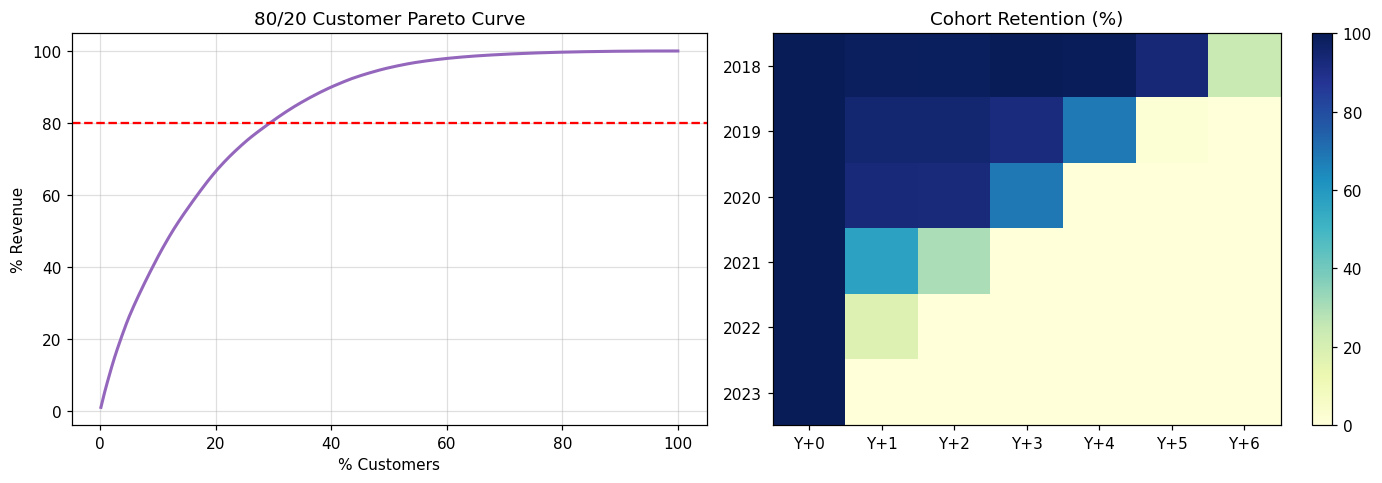

In [2]:
print("--- RFM Tier Summary ---\n", rfm_summary.round(2).to_string())
print("\n--- Annual Cohort Retention (%) ---\n", retention_pct.to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(cust_rev['cum_cust_pct'], cust_rev['cum_rev_pct'], color='#9467bd', lw=2)
ax[0].axhline(80, color='r', ls='--'); ax[0].set_title('80/20 Customer Pareto Curve'); ax[0].set_xlabel('% Customers'); ax[0].set_ylabel('% Revenue'); ax[0].grid(True, alpha=0.4)
im = ax[1].imshow(retention_pct.values, cmap='YlGnBu', aspect='auto', vmin=0, vmax=100)
ax[1].set_xticks(range(retention_pct.shape[1])); ax[1].set_xticklabels([f'Y+{i}' for i in retention_pct.columns])
ax[1].set_yticks(range(retention_pct.shape[0])); ax[1].set_yticklabels(retention_pct.index)
ax[1].set_title('Cohort Retention (%)'); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()


--- K-Means Customer Clusters ---
          recency  frequency  monetary  avg_discount_pct  avg_order_qty
Cluster                                                               
0          873.8       10.6    9677.1              42.2            1.7
1          318.7       62.6   68516.4              41.0            2.5
2          188.3      289.0  425055.0              41.7            3.9
3          224.2       38.2   51061.0              44.3            1.9


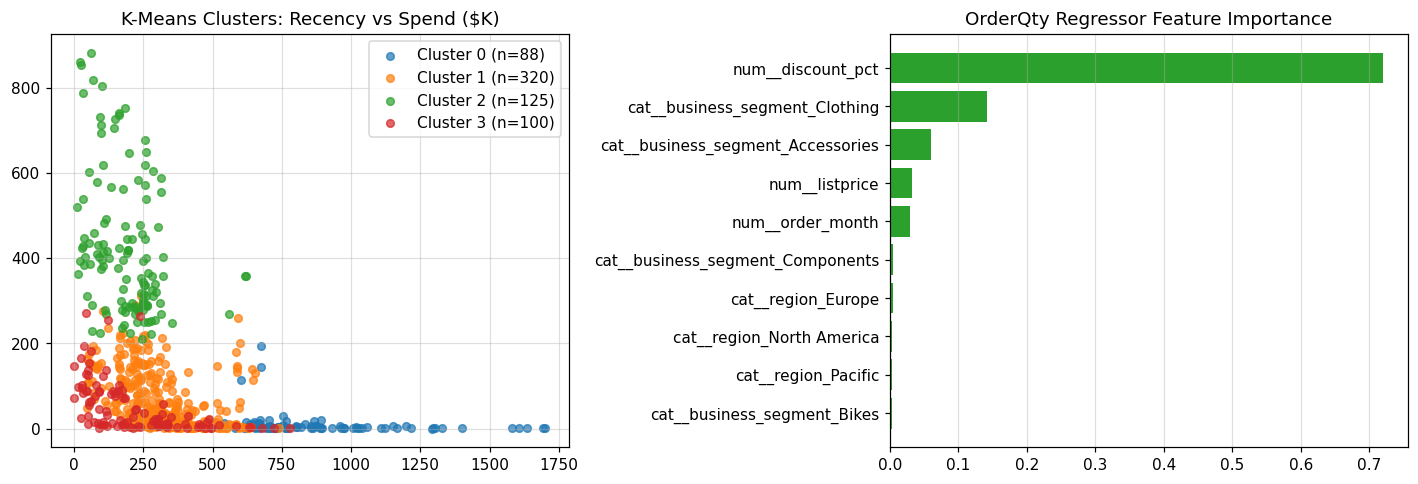

In [3]:
print("--- K-Means Customer Clusters ---\n", cust_features.groupby('Cluster').mean().round(1).to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for cid, col in enumerate(['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']):
    s = cust_features[cust_features['Cluster'] == cid]
    ax[0].scatter(s['recency'], s['monetary']/1e3, label=f'Cluster {cid} (n={len(s)})', alpha=0.7, s=25, color=col)
ax[0].set_title('K-Means Clusters: Recency vs Spend ($K)'); ax[0].legend(); ax[0].grid(True, alpha=0.4)
fn = reg_pipe.named_steps['prep'].get_feature_names_out()
imp = reg_pipe.named_steps['rf'].feature_importances_; idx = np.argsort(imp)
ax[1].barh(fn[idx], imp[idx], color='#2ca02c'); ax[1].set_title('OrderQty Regressor Feature Importance'); ax[1].grid(True, axis='x', alpha=0.4)
plt.tight_layout(); plt.show()
